In [1]:
from visualize import *
from data_generation import *   
from preprocessing import *
from sb import loss
from sb import model
from datasets.dataset import *
from torch.utils.data import DataLoader
import torch.nn.functional as F
import os
from PIL import Image
from scipy.interpolate import griddata
from tqdm import tqdm

In [2]:
high_f_1d = np.load("./data/kf_2d_re1000_256_40seed.npy", mmap_mode="r")
high_f_1d = high_f_1d[:40,:40,:,:]
low_f_1d = np.load("./data/low_fidelity_10%.npy", mmap_mode="r")
low_f_1d = low_f_1d[:40,:40,:,:]
print("GT high PDE (before downsampling) :", loss.phys_loss_kol(torch.tensor(high_f_1d), 1000))
print("GT low PDE (after downsampling) :", loss.phys_loss_kol(torch.tensor(low_f_1d), 1000))

/home/chan/miniconda3/envs/gtg/lib/python3.8/site-packages/torch/functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3549.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


GT high PDE (before downsampling) : tensor(0.7659, grad_fn=<MeanBackward0>)
GT low PDE (after downsampling) : tensor(238.1008, grad_fn=<MeanBackward0>)


In [3]:
mask_high_1d = make_sensor_mask(high_f_1d, n_sensors=256*25, sparse_ratio=None, seed=0)
mask_low_1d = make_sensor_mask(low_f_1d, n_sensors=256*25, sparse_ratio=None, seed=0)
# mask_high_1d = make_sensor_mask(high_f_1d, n_sensors=256*3, sparse_ratio=None, seed=0)
# mask_low_1d = make_sensor_mask(low_f_1d, n_sensors=256*3, sparse_ratio=None, seed=0)
# dataset_visualization(low_f_1d, mask_low_1d, batch_idx=10)
# dataset_visualization(high_f_1d, mask_high_1d, batch_idx=10)

In [4]:
N = low_f_1d.shape[0]
train_ratio = 0.8
val_ratio = 0.1

N_train = int(N * train_ratio)
# N_train = 1
N_val = int(N * val_ratio)
N_test = N - N_train - N_val

low_train  = low_f_1d[:N_train]
high_train = high_f_1d[:N_train]
mask_train = mask_high_1d[:N_train]

low_val  = low_f_1d[N_train:N_train + N_val]
high_val = high_f_1d[N_train:N_train + N_val]
mask_val = mask_high_1d[N_train:N_train + N_val]

low_test  = low_f_1d[N_train + N_val:]
high_test = high_f_1d[N_train + N_val:]
mask_test = mask_high_1d[N_train + N_val:]

ds_train = PDEPairDataset(low_data=low_train, high_data=high_train, mask_low_data=None, mask_high_data=mask_train)
dl_train = DataLoader(ds_train, batch_size=1, shuffle=True, drop_last=False)

ds_val = PDEPairDataset(low_data=low_val, high_data=high_val, mask_low_data=None, mask_high_data=mask_val)
dl_val = DataLoader(ds_val, batch_size=4, shuffle=False, drop_last=False)

ds_test = PDEPairDataset(low_data=low_test, high_data=high_test, mask_low_data=None, mask_high_data=mask_test)
dl_test = DataLoader(ds_test, batch_size=4, shuffle=False, drop_last=False)

In [5]:
sb_object = model.SB_model_ver1(train_dataloader=dl_train, val_dataloader=dl_val, timepoints=[0,1], time_dim=8, steps=10, base_lr=1e-4, save=True, pde_type='kolmo')

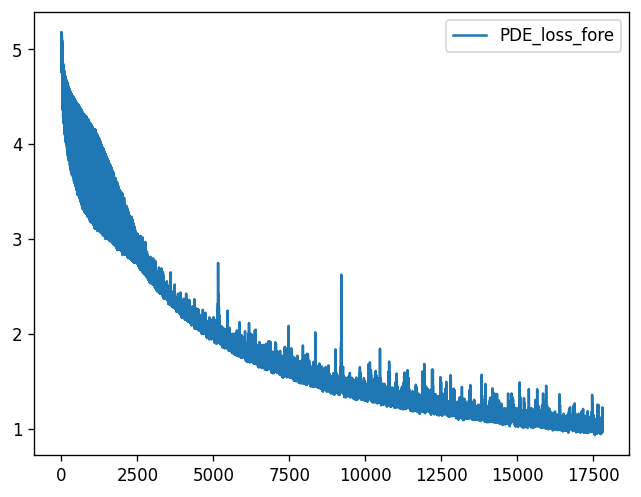

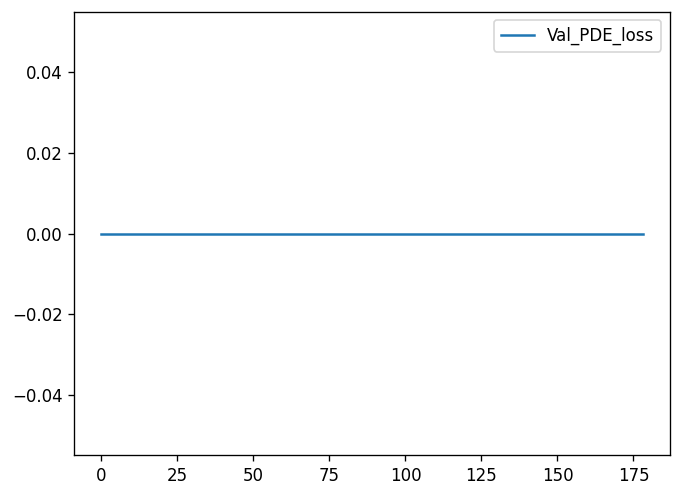

processed: 17873:  18%|█▊        | 18104/100000 [33:50<2:11:09, 10.41it/s, MSE_observed=0.08215693, PDE_loss=1.8536361, Val_PDE_loss=0, Alpha=0.0067153485] 

In [ ]:
sb_object.train(train_epochs=100000, model_name='kolmo_10%.pt', known_alpha=1000)

In [6]:
models_dict=torch.load('./model/train_test_split_kolmo_10%.pt')
# models_dict=torch.load('./model/kolmo_1%.pt')
sb_object.v_fore.load_state_dict(models_dict['v_fore'])
sb_object.time_embed.load_state_dict(models_dict['time_embed'])
sb_object.optimizer_fore.load_state_dict(models_dict['optimizer_fore'])
# print(models_dict['alpha'])
# print(models_dict['best_val_pde'])
# loss_history = print(models_dict['loss_history'])       

In [7]:
sb_object.v_fore.eval()
sb_object.time_embed.eval()

x0_chunks = []
m0_chunks = []
x1_chunks = []
m1_chunks = []
pred_chunks = []
with torch.no_grad():
    for x_0, x_1, mask_low, mask_high in dl_test:
        pred = sb_object.eval_fore(x_0=x_0, x_1=x_1, mask_low=mask_low, mask_high=mask_high)
        x0_chunks.append(x_0.detach().cpu())
        x1_chunks.append(x_1.detach().cpu())
        m0_chunks.append(mask_low.detach().cpu())
        m1_chunks.append(mask_high.detach().cpu())
        pred_chunks.append(pred.detach().cpu())

x0_all = torch.cat(x0_chunks, dim=0)
x1_all = torch.cat(x1_chunks, dim=0)
m0_all = torch.cat(m0_chunks, dim=0)
m1_all = torch.cat(m1_chunks, dim=0)
pred_all = torch.cat(pred_chunks, dim=0)
nwin, C, win_T, X = pred_all.shape
# x0_stitched = x0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# x1_stitched = x1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# m0_stitched = m0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# m1_stitched = m1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# pred_stitched = pred_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)

/home/chan/PISB/PI-BRIDGE/SyukeulimBridge/datasets/dataset.py:36: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)
  return torch.from_numpy(np.asarray(arr)).to(self.x_dtype)


/tmp/ipykernel_788461/1040438420.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dataA=torch.tensor(x0_all)[[1]],
/tmp/ipykernel_788461/1040438420.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dataB=torch.tensor(x1_all)[[1]],
/home/chan/PISB/PI-BRIDGE/SyukeulimBridge/visualize.py:267: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(u_tx).float(), torch.tensor(coef)


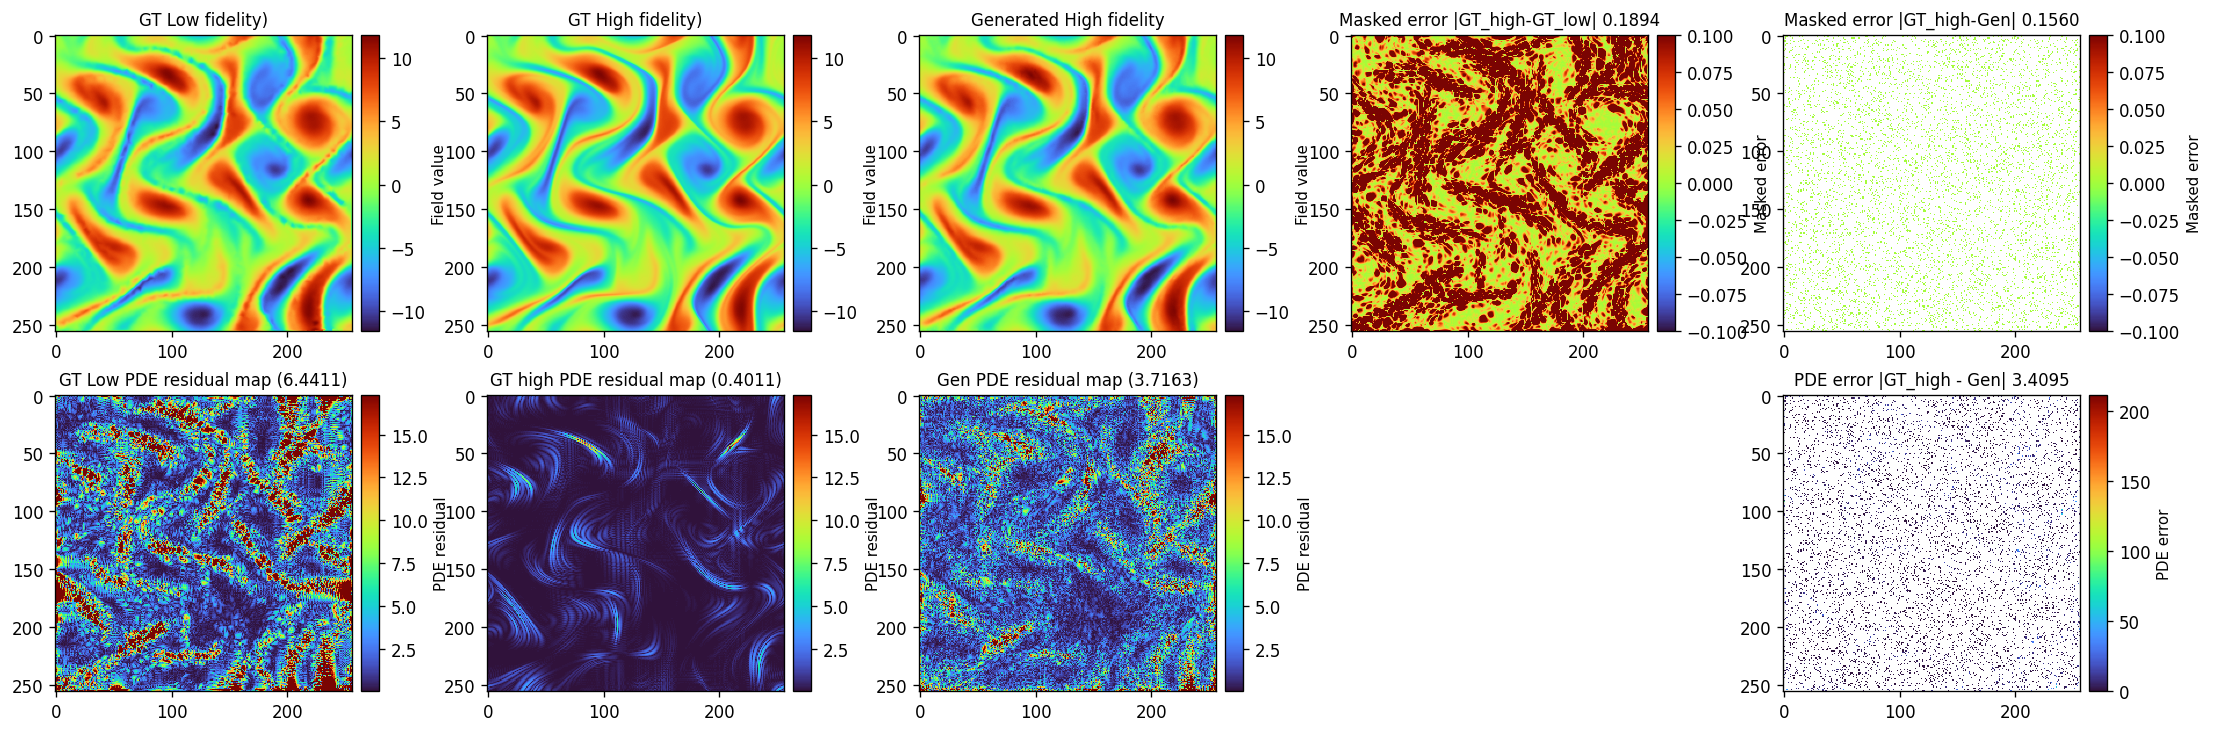

In [8]:
plot_result_3d(
    dataA=torch.tensor(x0_all)[[1]],                  
    dataB=torch.tensor(x1_all)[[1]],                  
    predict=pred_all[[1]],              
    high_resol_coef=1000,
    low_resol_coef=1000,
    snapshot_idx=23,
    mask=m1_all[[1]]           
)

In [11]:
def _to_device_float(x, device):
    if hasattr(x, "to"):
        return x.to(device=device, dtype=torch.float32, non_blocking=True)
    return torch.as_tensor(x, device=device, dtype=torch.float32)

def _to_device_bool(m, device):
    if m is None:
        return None
    if hasattr(m, "to"):
        return m.to(device=device, dtype=torch.bool, non_blocking=True)
    return torch.as_tensor(m, device=device, dtype=torch.bool)

def prepare_unet_input(low_data, high_data, mask_low, mask_high, device):
    low_data  = _to_device_float(low_data, device)
    high_data = _to_device_float(high_data, device)
    mask_low  = _to_device_bool(mask_low, device)
    mask_high = _to_device_bool(mask_high, device)

    B, C, H, W = low_data.shape

    # 1d case: (B,1,T,X) already represented as image (T x X)
    if C == 1:
        if mask_high is not None:
            x1_fixed = (high_data * mask_high).detach()
            low_data  = torch.where(mask_high, x1_fixed, low_data)
            high_data = torch.where(mask_high, x1_fixed, high_data)
        return low_data, high_data, mask_high, "1d"

    # 2d case: input comes as (B,T,X,Y) encoded as (B,C,H,W) with C=T
    # Keep time axis: convert to (B,1,T,X,Y)
    mask_ = mask_high
    if mask_ is not None:
        x1_fixed = (high_data * mask_).detach()
        low_data  = torch.where(mask_, x1_fixed, low_data)
        high_data = torch.where(mask_, x1_fixed, high_data)

    return low_data, high_data, mask_, "2d_time_as_channel"

In [12]:
sb_object.v_fore.eval()
sb_object.time_embed.eval()
with torch.no_grad():
    x0_fix, x1_fix, mask_fix, mod = prepare_unet_input(x_0, x_1, mask_low, mask_high, 'cuda')
    x_last = sb_object.fwd_start_from_t(x_0=x0_fix, x_1_fixed=x1_fix, mask=mask_fix, v_m=sb_object.v_fore, t_m=sb_object.time_embed, one_step=True)

/tmp/ipykernel_788461/3993400305.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dataA=torch.tensor(x0_all)[[1]],
/tmp/ipykernel_788461/3993400305.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dataB=torch.tensor(x1_all)[[1]],


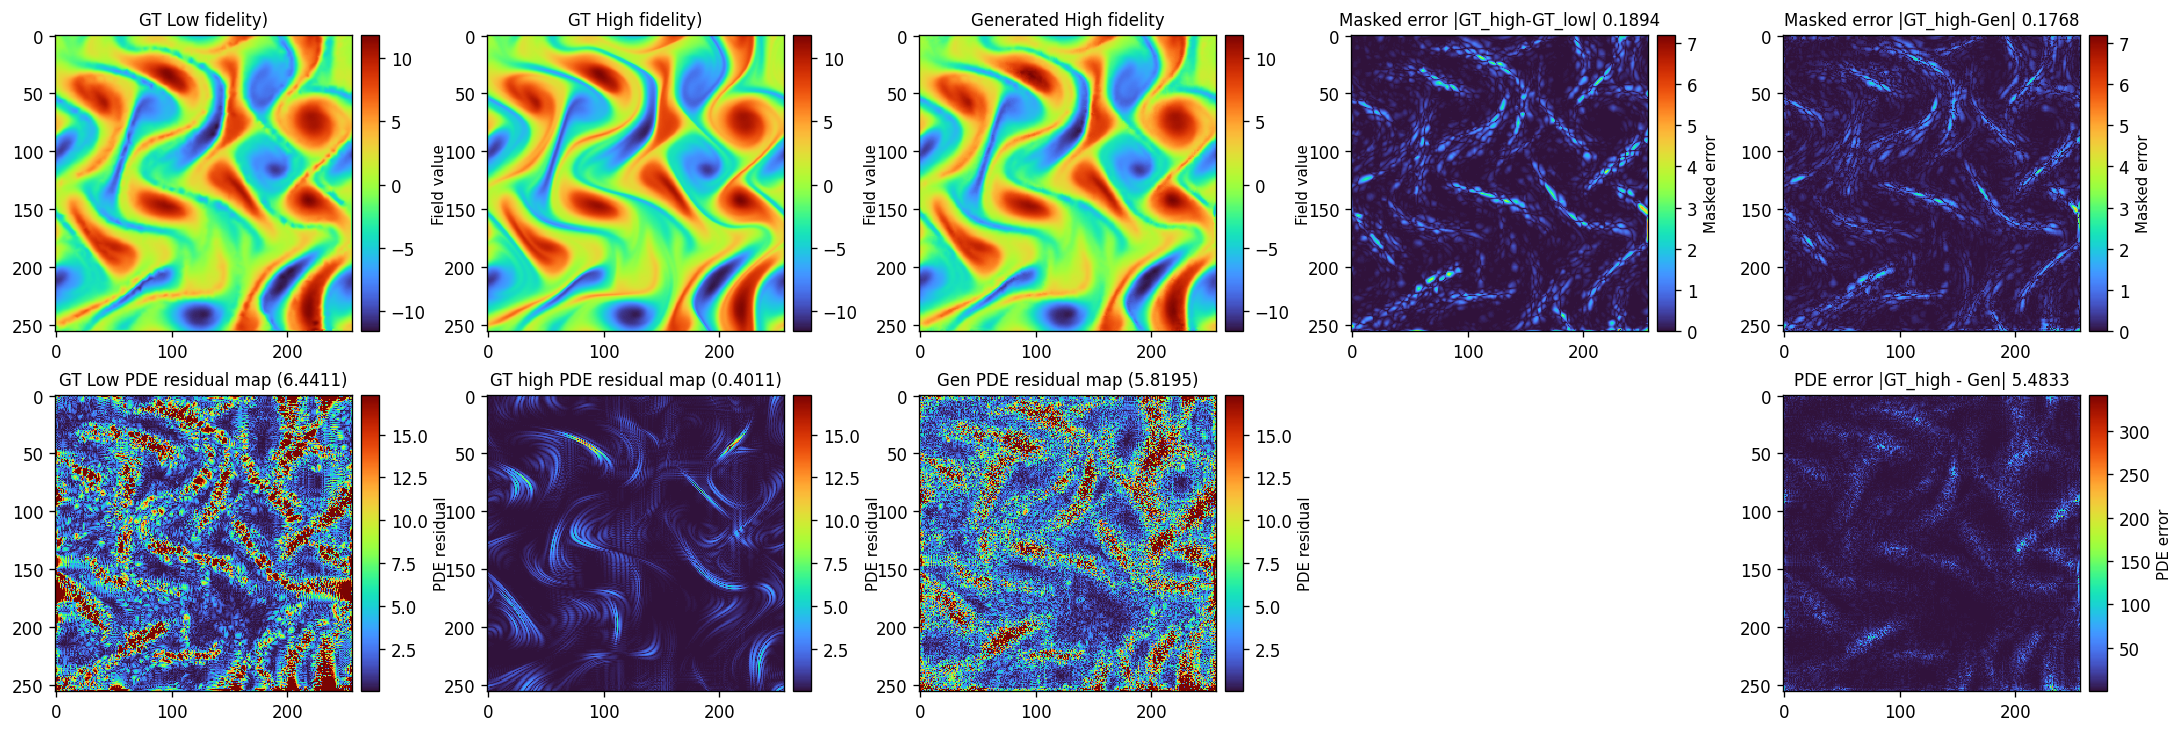

In [16]:
plot_result_3d(
    dataA=torch.tensor(x0_all)[[1]],                  
    dataB=torch.tensor(x1_all)[[1]],                  
    predict=x_last[[1]],              
    high_resol_coef=1000,
    low_resol_coef=1000,
    snapshot_idx=23,
    # mask=m1_all[[1]]           
)